In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Torch version: {torch.__version__}")
print(f"Using device: {device}")

Torch version: 2.14.1+cu132
Using device: cuda


In [2]:
from transformers import AutoTokenizer, AutoModelForCausalLM, ViTModel, ViTImageProcessor
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

/home/viraj/Projects/vision-language-models-notebooks-scripts/.vlm_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
from datasets import load_dataset
from PIL import Image
import requests
from io import BytesIO
import warnings
warnings.filterwarnings('ignore')

# Vision Encoders
- Vision encoder converts image into feature vectors.
- These feature vectors are used to pre-train Vision Transformer [ViT]
The Steps are as follows:
1. Splits image into 16x16 patches
2. Projects the patches into embeddings
3. Process patches through transformers layers
4. Outputs feature vectors (One per Patch + CLS token)

Calculation 224 x 224 image with 16 x 16 patches ->
* (224 / 16) x (224 / 16) = 14 x 14 = 196 patches
* 196 + 1 = 197 tokens 
* Each tokens has dimensions 1024

In [4]:
vision_model_name = "google/vit-base-patch16-224-in21k"
vision_model = ViTModel.from_pretrained(vision_model_name).to(device)
img_processor = ViTImageProcessor.from_pretrained(vision_model_name)

Loading weights: 100%|██████████| 200/200 [00:00<00:00, 12603.08it/s]


In [5]:
for param in vision_model.parameters():
    param.requires_grad = False

vision_model.eval()
print(f"Vision Model hidden size : {vision_model.config.hidden_size}")
print(f"Number of patches : {(224//16)**2} + 1 CLS Token = {(224//16)**2 + 1}")

Vision Model hidden size : 768
Number of patches : 196 + 1 CLS Token = 197


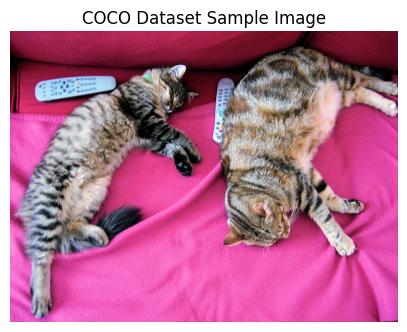

In [6]:
url = "http://images.cocodataset.org/val2017/000000039769.jpg"
response = requests.get(url)
sample_img = Image.open(BytesIO(response.content))
plt.figure(figsize=(5, 5))
plt.imshow(sample_img)
plt.axis('off')
plt.title("COCO Dataset Sample Image")
plt.show()

In [7]:
inputs = img_processor(images=sample_img, return_tensors="pt").to(device)
with torch.no_grad():
    vision_outputs = vision_model(**inputs)
img_feature_vec = vision_outputs.last_hidden_state
print(f"Image feature vector shape : {img_feature_vec.shape}")
print(f"Image feature vector : {img_feature_vec[0, 0, :5]} ... {img_feature_vec[0, 0, -5:]}")

Image feature vector shape : torch.Size([1, 197, 768])
Image feature vector : tensor([ 0.1563,  0.0906,  0.1513, -0.0204, -0.0531], device='cuda:0') ... tensor([ 0.1795, -0.0717, -0.3184, -0.0863, -0.0908], device='cuda:0')


# Language Model
For Language models SmolLM - 360M small but capable language model from HF

* 360M Params [Anything >135M Params for better performance]
* Hidden dimensions of 960M
* Modest Hardware

In [8]:
lm_model_name = "HuggingFaceTB/SmolLM-360M"
lm_tokenizer = AutoTokenizer.from_pretrained(lm_model_name)
lm = AutoModelForCausalLM.from_pretrained(lm_model_name).to(device)

if lm_tokenizer.pad_token is None:
    lm_tokenizer.pad_token = lm_tokenizer.eos_token

print(f"Language Model Hidden Size : {lm.config.hidden_size}")
print(f"Vocabulary Size : {lm.config.vocab_size}")
print(f"Number of layers : {lm.config.num_hidden_layers}")

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 3628.45it/s]


Language Model Hidden Size : 960
Vocabulary Size : 49152
Number of layers : 32


In [9]:
test_txt = "A photo of"
inputs = lm_tokenizer(test_txt, return_tensors="pt").to(device)

with torch.no_grad():
    ouputs = lm.generate(
        **inputs,
        max_new_tokens=50,
        do_sample=True,
        temperature=0.7,
        pad_token_id=lm_tokenizer.pad_token_id
    )
print(f"Generate Test : {lm_tokenizer.decode(ouputs[0], )}")

Generate Test : A photo of the "Great War" and the "Great War" with its "great numbers of dead" and "great numbers of wounded" and "great number of prisoners" (or "enemy prisoners" in the case of the Chinese) (see also


# The Projection Layer
The projection layer is the bridge between vision and language.

From : Vision Feature Vector (Batch, 197, 1024)
To : Language Embedding  (Batch, 197, 960)

Use simple multi-layer projection with :
1. Linear Layer (1024 -> 960)
2. GELU activation
3. Layer Norm for stability

Similar to LLaVA

In [10]:
class VisionProjector(nn.Module):
    def __init__(self, vision_dim:int, language_dim:int):
        super().__init__()
        self.projection = nn.Sequential(
            nn.Linear(vision_dim, language_dim),
            nn.GELU(),
            nn.LayerNorm(language_dim),
            nn.Linear(language_dim, language_dim)
        )

    def forward(self, vision_features: torch.Tensor) -> torch.Tensor:
        return self.projection(vision_features)

vision_dim = vision_model.config.hidden_size
lm_dim = lm.config.hidden_size

projector = VisionProjector(vision_dim, lm_dim).to(device)
print(f"Projector : {vision_dim} -> {lm_dim}")
print(f"Trainable params : {sum(p.numel() for p in projector.parameters()):,}")

Projector : 768 -> 960
Trainable params : 1,662,720


In [11]:
with torch.no_grad():
    projected_features = projector(img_feature_vec)
print(f"Image feature vector shape : {img_feature_vec.shape}")
print(f"Language model feature vector shape : {projected_features.shape}")
print(f"Projected feature vector shape : {projected_features.shape}")
print(f"Projected feature vector : {projected_features[0, 0, :5]} ... {projected_features[0, 0, -5:]}")

Image feature vector shape : torch.Size([1, 197, 768])
Language model feature vector shape : torch.Size([1, 197, 960])
Projected feature vector shape : torch.Size([1, 197, 960])
Projected feature vector : tensor([ 0.6652,  0.6788, -0.0244,  0.0477, -0.0722], device='cuda:0') ... tensor([ 0.3291,  0.5253,  0.0048, -0.4391,  0.3842], device='cuda:0')


In [12]:
class MiniVLM(nn.Module):
    def __init__(self, 
                vit : ViTModel,
                lt : AutoModelForCausalLM,
                projector : VisionProjector,
                tokenizer : AutoTokenizer
    ):
        super().__init__()
        self.vit = vit
        self.lt = lt
        self.projector = projector
        self.tokenizer = tokenizer

        for param in self.vit.parameters():
            param.requires_grad = False

    def encode_image(self, pixel_values : torch.Tensor) -> torch.Tensor:
        with torch.no_grad():
            vision_op = self.vit(pixel_values=pixel_values)
        image_features = vision_op.last_hidden_state
        projected = self.projector(image_features)
        return projected

    def forward(self, 
        pixel_values: torch.Tensor,
        input_ids: torch.Tensor,
        attention_mask: torch.Tensor,
        labels: torch.Tensor = None
    ):
        batch_size = pixel_values.shape[0]
        img_embeds = self.encode_image(pixel_values)
        num_image_tokens = img_embeds.shape[1]
        text_embeds = self.lt.get_input_embeddings()(input_ids)
        combined_embeds = torch.cat([img_embeds, text_embeds], dim = 1)
        img_attention = torch.ones(
            (batch_size, num_image_tokens),
            dtype = attention_mask.dtype,
            device = attention_mask.device
        )
        combined_attention = torch.cat([img_attention, attention_mask], dim=1)
        if labels is not None:
            img_labels = torch.full(
                (batch_size, num_image_tokens),
                fill_value=-100,
                dtype=labels.dtype,
                device=labels.device
            )
            combined_lables = torch.cat([img_labels, labels], dim=1)
        else:
            combined_lables = None

        outputs = self.lt(
            inputs_embeds = combined_embeds,
            attention_mask = combined_attention,
            labels = combined_lables,
            return_dict = True
        )
        return outputs

    @torch.no_grad()
    def generate(
        self, 
        pixel_values: torch.Tensor,
        max_new_tokens: int = 50,
        temperature: float = 0.7,
        do_sample: bool = True
    ):
        self.eval()
        img_embeds = self.encode_image(pixel_values)
        prompt = "This Image Shows "
        prompt_ids = self.tokenizer.encode(prompt, return_tensors="pt").to(pixel_values.device)
        prompt_embeds = self.language_model.get_input_embeddings()(prompt_ids)
        combined_embeds = torch.cat([img_embeds, prompt_embeds], dim=1)
        generated_ids = prompt_ids.clone()

        for _ in range(max_new_tokens):
            current_embeds = self.lt.get_input_embeddings()(generated_ids)
            full_embeds = torch.cat([img_embeds, current_embeds], dim=1)
            outputs = self.lt(inputs_embeds = full_embeds)
            next_token_logits = outputs.logits[:, -1, :]

            if do_sample:
                probs = F.softmax(next_token_logits / temperature, dim = -1)
                next_token = torch.multinomial(probs, num_samples=1)
            else:
                next_token = next_token_logits.argmax(dim=-1, keepdim=True)

            generated_ids = torch.cat([generated_ids, next_token], dim=1)

            if next_token.item() == self.tokenizer.eos_token_id:
                break
        return self.tokenizer.decode(generated_ids[0], skip_special_tokens=True)

VLM = MiniVLM(
    vit = vision_model,
    lt = lm,
    projector=projector,
    tokenizer=lm_tokenizer
).to(device)

total_params = sum(p.numel() for p in VLM.parameters())
trainable_params = sum(p.numel() for p in VLM.parameters() if p.requires_grad)

print(f"Total Parameters : {total_params}")
print(f"Trainable Parameters : {trainable_params}")
print(f"Frozen Parameters : {total_params - trainable_params}")

Total Parameters : 449873088
Trainable Parameters : 363483840
Frozen Parameters : 86389248


# Part 5 Loading the Flickr 8k Dataset
* Using subset of Flickr - 8k datset
* Popular image captioning benchmark with 8K images with 5 captions
* Randomly selecting one per image during training 

In [13]:
dataset = load_dataset("jxie/flickr8k", split="train")
num_samples = 2000
dataset = dataset.shuffle(seed=42).select(range(num_samples))
print(f"Dataset Size : {len(dataset)}")
print(f"Sample item key {dataset[0].keys()}")

Generating test split: 100%|██████████| 1000/1000 [00:00<00:00, 3174.69 examples/s]

Dataset Size : 2000
Sample item key dict_keys(['image', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4'])


Image : <class 'PIL.JpegImagePlugin.JpegImageFile'>
Captions:
 0: Boys with their backs against an incoming wave .
 1: Four boys are about to be hit by an approaching wave .
 2: Four people sitting in the path of a wave .
 3: Four young men are sitting on the beach under a crashing wave .
 4: three boys sitting in sand getting splashed by wave


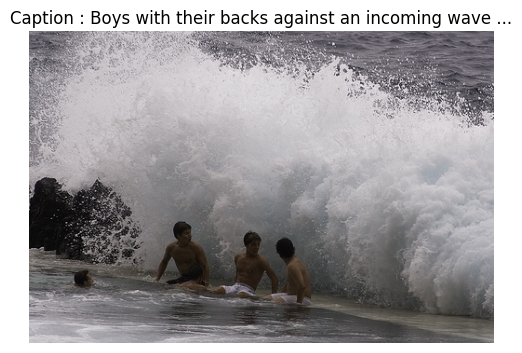

In [16]:
sample = dataset[0]
print(f"Image : {type(sample['image'])}")
print(f"Captions:")
for i in range(5):
    print(f" {i}: {sample[f'caption_{i}']}")

plt.figure(figsize=(6,6))
plt.imshow(sample['image'])
plt.title(f"Caption : {sample['caption_0'][:60]}..")
plt.axis('off')
plt.show()